# Laboratory 04 — Logistic Regression Analysis for Diabetes Prediction
**Course:** Introduction to Artificial Intelligence (AI-101L)  
**Instructor:** Dr. Muhammad Awais  
**Topic:** Supervised Classification — Medical Risk Prediction and Probability Estimation

---

## 1. Theoretical Background
Logistic Regression is the foundational algorithm for binary classification. Unlike linear regression, which predicts an unbounded continuous output, logistic regression models the conditional probability that a binary target $y \in \{0, 1\}$ belongs to class 1:

$$P(y=1|\mathbf{x}) = \sigma(\mathbf{w}^T \mathbf{x} + b) = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x} + b)}}$$

The log-odds (logit transformation) provides an interpretable linear relationship:
$$\ln\left(\frac{P}{1-P}\right) = \beta_0 + \sum_{j=1}^m \beta_j x_j$$

Model parameters are optimized by minimizing the Binary Cross-Entropy (Log-Loss) function:
$$\mathcal{L}(\mathbf{w}, b) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \ln(\hat{p}_i) + (1 - y_i) \ln(1 - \hat{p}_i) \right]$$


In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Clinical Dataset Ingestion and Preprocessing

In [2]:
# Load the dataset (portable relative path)
data_path = "diabetes.csv"
if not os.path.exists(data_path):
    data_path = os.path.join(os.path.dirname(__file__) if '__file__' in locals() else '.', "diabetes.csv")

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]} patients, {df.shape[1]} features")
print("\nFirst 5 Records:")
display(df.head())


Dataset Shape: 768 patients, 8 features

First 5 Records:
   Glucose  BloodPressure  ...  Age  Outcome
0      148           72.0  ...   50        1
1       85           66.0  ...   31        0
2      183           64.0  ...   32        1
3       89           66.0  ...   21        0
4      137           40.0  ...   33        1

[5 rows x 8 columns]


In [3]:
# Clinical inspection: Detecting zero values in biologically positive attributes
zero_fields = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
zero_counts = {col: (df[col] == 0).sum() for col in zero_fields if col in df.columns}
print("Clinically Implausible Zero Value Count (Missing Data Mask):")
for col, cnt in zero_counts.items():
    print(f"  - {col:15}: {cnt} zeroes ({cnt/len(df)*100:.1f}%)")

# Class balance
outcome_counts = df['Outcome'].value_counts()
print(f"\nClass Distribution: Negative (0) = {outcome_counts[0]}, Positive (1) = {outcome_counts[1]}")


Clinically Implausible Zero Value Count (Missing Data Mask):
  - Glucose        : 0 zeroes (0.0%)
  - BloodPressure  : 0 zeroes (0.0%)
  - SkinThickness  : 0 zeroes (0.0%)
  - Insulin        : 0 zeroes (0.0%)
  - BMI            : 0 zeroes (0.0%)

Class Distribution: Negative (0) = 500, Positive (1) = 268


## 3. Feature Selection, Splitting and Standardization
We select the 6 key predictive clinical features aligned with deployment specs:
`['Glucose', 'BloodPressure', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']`.
Standardization ($\mu=0, \sigma=1$) is performed to ensure consistent gradient updates.


In [4]:
selected_features = ['Glucose', 'BloodPressure', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
X = df[selected_features].copy()
y = df['Outcome'].copy()

# Stratified split to preserve class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standard scaling
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=selected_features)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=selected_features)

print(f"Training set: {len(X_train)} samples | Test set: {len(X_test)} samples")


Training set: 614 samples | Test set: 154 samples


## 4. Logistic Regression Model Training & Interpretation

In [5]:
# Initialize and train logistic regression
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# Calculate Odds Ratios: exp(beta_j)
odds_ratios = np.exp(model.coef_[0])
coef_table = pd.DataFrame({
    'Clinical Feature': selected_features,
    'Log-Odds Weight (beta)': model.coef_[0],
    'Odds Ratio [exp(beta)]': odds_ratios
}).sort_values(by='Odds Ratio [exp(beta)]', ascending=False).reset_index(drop=True)

print(f"Model Intercept (beta_0): {model.intercept_[0]:.4f}\n")
print("Learned Clinical Weights and Odds Ratios:")
print(coef_table.to_string(index=False))


Model Intercept (beta_0): -9.8103

Learned Clinical Weights and Odds Ratios:
        Clinical Feature  Log-Odds Weight (beta)  Odds Ratio [exp(beta)]
DiabetesPedigreeFunction                0.442773                1.557019
                     BMI                0.087898                1.091877
                 Glucose                0.031282                1.031776
                     Age                0.027550                1.027933
                 Insulin                0.007948                1.007979
           BloodPressure                0.000796                1.000797


## 5. Comprehensive Model Evaluation
We evaluate classification performance across Accuracy, Precision, Recall, F1-Score, Confusion Matrix, and ROC-AUC.


In [6]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("=== Classification Performance Metrics on Test Set ===")
print(f"Accuracy  : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision : {prec:.4f} (True Positive predictive value)")
print(f"Recall    : {rec:.4f} (Sensitivity / Detection rate)")
print(f"F1-Score  : {f1:.4f} (Harmonic mean of precision & recall)")
print(f"ROC AUC   : {auc:.4f} (Discrimination capability)\n")

print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Non-Diabetic', 'Diabetic']))


=== Classification Performance Metrics on Test Set ===
Accuracy  : 0.7403 (74.03%)
Precision : 0.6522 (True Positive predictive value)
Recall    : 0.5556 (Sensitivity / Detection rate)
F1-Score  : 0.6000 (Harmonic mean of precision & recall)
ROC AUC   : 0.8091 (Discrimination capability)

Detailed Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.78      0.84      0.81       100
    Diabetic       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154



<ipython-input-1-f60ca84fbdf2>:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


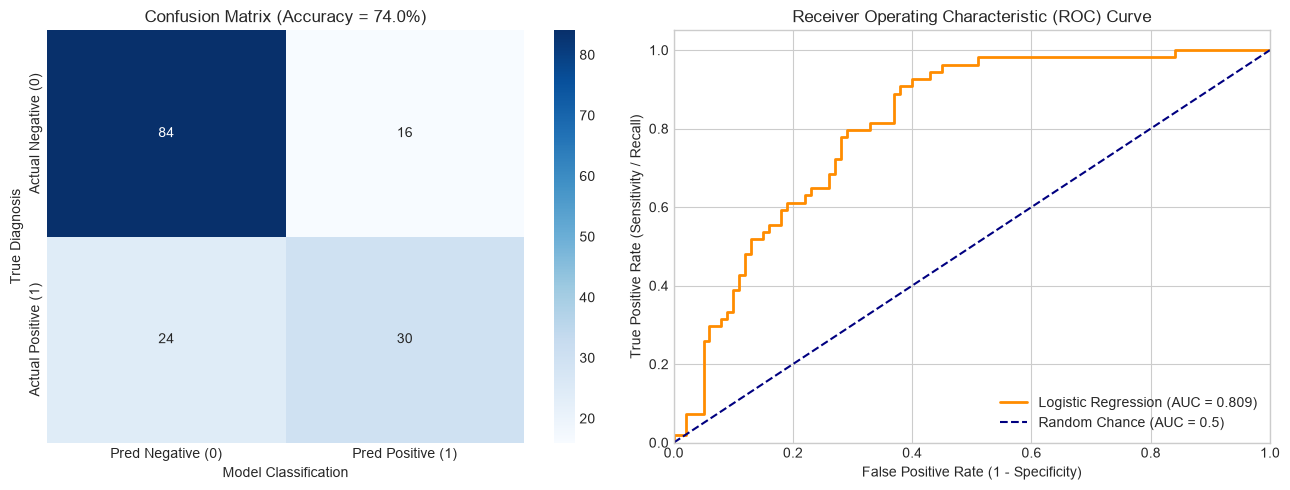

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred Negative (0)', 'Pred Positive (1)'],
            yticklabels=['Actual Negative (0)', 'Actual Positive (1)'])
axes[0].set_title(f"Confusion Matrix (Accuracy = {acc*100:.1f}%)", fontsize=12)
axes[0].set_ylabel("True Diagnosis")
axes[0].set_xlabel("Model Classification")

# 2. Receiver Operating Characteristic (ROC) Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'Logistic Regression (AUC = {auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.5)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (1 - Specificity)')
axes[1].set_ylabel('True Positive Rate (Sensitivity / Recall)')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=12)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


## 6. Single-Patient Inference & Model Persistence
*(Fixing the legacy syntax error cell 7 by structuring the patient test record)*


In [8]:
# Patient test vector: Age=21, BMI=35.7, BloodPressure=75.0, Insulin=102.5, Glucose=112, DPF=0.148
patient_sample = pd.DataFrame([{
    'Glucose': 112.0,
    'BloodPressure': 75.0,
    'Insulin': 102.5,
    'BMI': 35.7,
    'DiabetesPedigreeFunction': 0.148,
    'Age': 21.0
}])[selected_features]

sample_pred = model.predict(patient_sample)[0]
sample_prob = model.predict_proba(patient_sample)[0][1]

print("=== Single Clinical Record Inference ===")
print("Patient Profile:")
for k, v in patient_sample.iloc[0].items():
    print(f"  - {k:25}: {v}")
print(f"\nModel Predicted Class : {sample_pred} ({'Diabetic' if sample_pred == 1 else 'Non-Diabetic'})")
print(f"Diabetic Probability  : {sample_prob:.4f} ({sample_prob*100:.1f}%)")


=== Single Clinical Record Inference ===
Patient Profile:
  - Glucose                  : 112.0
  - BloodPressure            : 75.0
  - Insulin                  : 102.5
  - BMI                      : 35.7
  - DiabetesPedigreeFunction : 0.148
  - Age                      : 21.0

Model Predicted Class : 0 (Non-Diabetic)
Diabetic Probability  : 0.1611 (16.1%)


In [9]:
# Export model artifact for Lab 06 deployment
model_export_path = "Mymdoel.pkl"
with open(model_export_path, "wb") as f:
    pickle.dump(model, f)

print(f"Model successfully saved to '{model_export_path}' for deployment in Lab 06.")


Model successfully saved to 'Mymdoel.pkl' for deployment in Lab 06.
